In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

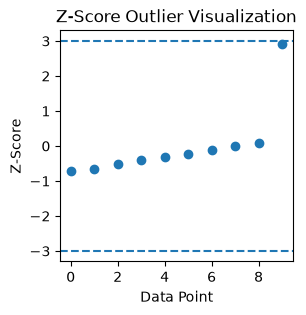

In [ ]:
#                                                      IQR, Z-score Visualization

from scipy.stats import zscore

data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(3,3))
plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()



{'whiskers': [<matplotlib.lines.Line2D at 0x153389d1d30>,
 'caps': [<matplotlib.lines.Line2D at 0x153389d1fd0>,
 'boxes': [<matplotlib.lines.Line2D at 0x153389d1be0>],
 'medians': [<matplotlib.lines.Line2D at 0x153389d2270>],
 'fliers': [<matplotlib.lines.Line2D at 0x153389d23c0>],
 'means': []}

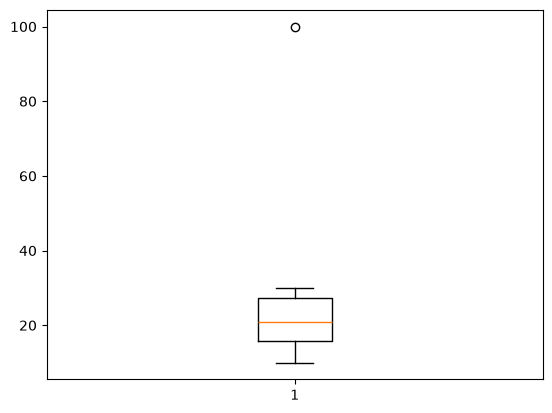

In [5]:
plt.boxplot(data)

In [7]:
df=sns.load_dataset('tips')

In [8]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


{'whiskers': [<matplotlib.lines.Line2D at 0x1533a86c590>,
 'caps': [<matplotlib.lines.Line2D at 0x1533a86c830>,
 'boxes': [<matplotlib.lines.Line2D at 0x1533a86c440>],
 'medians': [<matplotlib.lines.Line2D at 0x1533a86cad0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1533a86cc20>],
 'means': []}

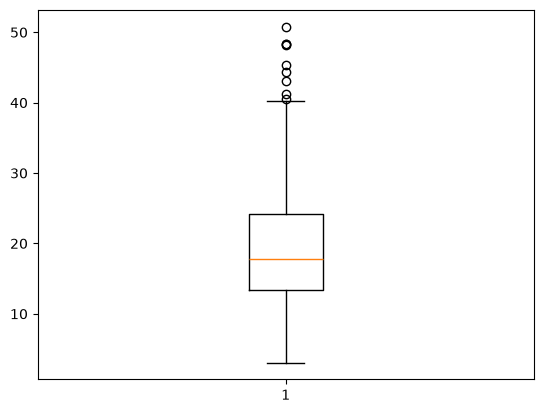

In [20]:
plt.boxplot(df['total_bill'])

In [16]:
q1=df['total_bill'].quantile(0.25)
q3=df['total_bill'].quantile(0.75)
iqr=q3-q1
print('iqr----',iqr)

lower=q3-q1

lower=q1-1.5*iqr


upper=q3+1.5*iqr

df[(df['total_bill']<upper) & (df['total_bill']>lower)]

iqr---- 10.779999999999998


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [27]:
df.shape

(244, 7)

In [26]:
q1=df['tip'].quantile(0.25)
q3=df['tip'].quantile(0.75)
iqr=q3-q1
print('iqr----',iqr)
lower=q3-q1
lower=q1-1.5*iqr
print('lower-------', lower)
upper=q3+1.5*iqr
print('upper--------',upper)

iqr---- 1.5625
lower------- -0.34375
upper-------- 5.90625


{'whiskers': [<matplotlib.lines.Line2D at 0x1533a86f620>,
 'caps': [<matplotlib.lines.Line2D at 0x1533a86f8c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1533a86f4d0>],
 'medians': [<matplotlib.lines.Line2D at 0x1533a86fb60>],
 'fliers': [<matplotlib.lines.Line2D at 0x1533a86fcb0>],
 'means': []}

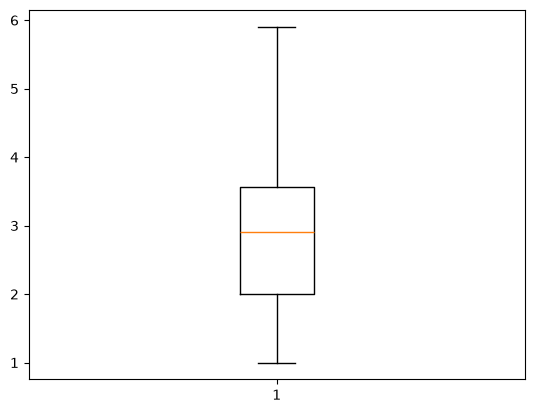

In [ ]:
#                                                         removal vs capping


df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

In [33]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01000,Female,No,Sun,Dinner,2
1,10.34,1.66000,Male,No,Sun,Dinner,3
2,21.01,3.50000,Male,No,Sun,Dinner,3
3,23.68,3.31000,Male,No,Sun,Dinner,2
4,24.59,3.61000,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.90625,Male,No,Sat,Dinner,3
240,27.18,2.00000,Female,Yes,Sat,Dinner,2
241,22.67,2.00000,Male,Yes,Sat,Dinner,2
242,17.82,1.75000,Male,No,Sat,Dinner,2


In [ ]:
# Impact on models, ColumnTransformer ,Pipeline 

\\\\
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder,MinMaxScaler
from sklearn.compose import ColumnTransformer

In [ ]:
\df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [41]:
num_fea=['total_bill','tip']
ohe_fea=['sex','smoker']
min_max=['tip']

In [ ]:
from sklearn.preprocessing import MinMaxScaler
transform=ColumnTransformer(
transformers=[('num',StandardScaler(),num_fea),
('min_max', MinMaxScaler(),min_max),
('cat',OneHotEncoder(),ohe_fea),
], remainder='passthrough'aA\

)

In [50]:
transform.fit_transform(df)

array([[-0.3147113050904943, -1.586160695895674, 0.002038216560509565,
        ..., 'Sun', 'Dinner', 2],
       [-1.0632353132988692, -1.0547221187494287, 0.13452229299363055,
        ..., 'Sun', 'Dinner', 3],
       [0.13777989987156145, 0.449657853479943, 0.5095541401273886, ...,
        'Sun', 'Dinner', 3],
       ...,
       [0.3246295019205694, -0.7767388630113925, 0.20382165605095542,
        ..., 'Sat', 'Dinner', 2],
       [-0.2212865040659901, -0.9811383157599484, 0.15286624203821658,
        ..., 'Sat', 'Dinner', 2],
       [-0.11322890288102155, 0.04085894798283116, 0.4076433121019109,
        ..., 'Thur', 'Dinner', 2]], shape=(244, 10), dtype=object)

In [51]:
pd.DataFrame(transform.fit_transform(df), columns=transform.get_feature_names_out())

,num__total_bill,num__tip,min_max__tip,cat__sex_Female,cat__sex_Male,cat__smoker_No,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-0.314711,-1.586161,0.002038,1.0,0.0,1.0,0.0,Sun,Dinner,2
1,-1.063235,-1.054722,0.134522,0.0,1.0,1.0,0.0,Sun,Dinner,3
2,0.13778,0.449658,0.509554,0.0,1.0,1.0,0.0,Sun,Dinner,3
3,0.438315,0.294314,0.470828,0.0,1.0,1.0,0.0,Sun,Dinner,2
4,0.540745,0.539594,0.531975,1.0,0.0,1.0,0.0,Sun,Dinner,4
...,...,...,...,...,...,...,...,...,...,...
239,1.040511,2.417003,1.0,0.0,1.0,1.0,0.0,Sat,Dinner,3
240,0.832275,-0.776739,0.203822,1.0,0.0,0.0,1.0,Sat,Dinner,2
241,0.32463,-0.776739,0.203822,0.0,1.0,0.0,1.0,Sat,Dinner,2
242,-0.221287,-0.981138,0.152866,0.0,1.0,1.0,0.0,Sat,Dinner,2
